# Лабораторная работа №5. Линейная регрессия
Елич М., гр. 5130904/30102

## Задание 1. Выбор зависимой переменной в линейной регрессии
По набору reglab1.txt построить линейные регрессии с разными зависимыми переменными и выбрать наиболее подходящую модель.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split, KFold, cross_val_score, GridSearchCV
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# Задание 1: reglab1.txt - выбор зависимой переменной
d1 = pd.read_csv('reglab1.txt', sep='\t')
print('reglab1:', d1.shape, '| столбцы:', list(d1.columns))
print(d1.describe().loc[['min','max','mean']].round(3).to_dict())

def ols_fit(df, target):
    X = df.drop(columns=target).values; y = df[target].values
    m = LinearRegression().fit(X, y)
    r2 = m.score(X, y); n, p = X.shape
    adj = 1 - (1 - r2) * (n - 1) / (n - p - 1)
    return m, r2, adj

rows1 = []
for col in d1.columns:
    m, r2, adj = ols_fit(d1, col)
    feats = [c for c in d1.columns if c != col]
    eq = f'{col} = {m.intercept_:.3f} ' + ' '.join(f'{c:+.3f}·{f}' for c, f in zip(m.coef_, feats))
    rows1.append({'отклик': col, 'R²': r2, 'adj R²': adj, 'уравнение': eq})
tab1 = pd.DataFrame(rows1)
print(tab1.round(3).to_string(index=False))

reglab1: (200, 3) | столбцы: ['z', 'x', 'y']
{'z': {'min': 1.279, 'max': 9.569, 'mean': 4.527}, 'x': {'min': 0.013, 'max': 0.995, 'mean': 0.505}, 'y': {'min': 0.007, 'max': 0.995, 'mean': 0.501}}
отклик    R²  adj R²                    уравнение
     z 0.969   0.968 z = -0.022 +4.102·x +4.943·y
     x 0.919   0.918  x = 0.045 +0.224·z -1.106·y
     y 0.951   0.950  y = 0.029 +0.192·z -0.788·x


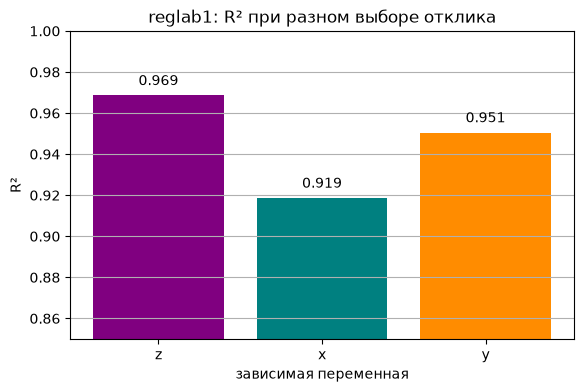

,отклик,R²,adj R²
0,z,0.969,0.968
1,x,0.919,0.918
2,y,0.951,0.950


In [2]:
# Рис.1: R² трёх моделей
plt.figure(figsize=(6.5, 4))
plt.bar(tab1['отклик'], tab1['R²'], color=['purple','teal','darkorange'])
for i, v in enumerate(tab1['R²']): plt.text(i, v + 0.005, f'{v:.3f}', ha='center')
plt.ylim(0.85, 1.0); plt.ylabel('R²'); plt.xlabel('зависимая переменная')
plt.title('reglab1: R² при разном выборе отклика'); plt.grid(True, axis='y')
plt.show()
tab1[['отклик','R²','adj R²']].round(3)

### Выводы по заданию 1
Из трёх возможных назначений зависимой переменной лучшее качество даёт регрессия z по двум оставшимся столбцам: R² = 0.969. Сравнение выполнено по R², а не по остаточной сумме квадратов, потому что столбцы измерены в разных масштабах.

## Задание 2. Сокращение числа признаков перебором подмножеств
Для данных reglab.txt реализовать перебор подмножеств: для каждого k от 0 до d найти набор признаков мощности k с минимальной остаточной суммой квадратов RSS и по этому перебору выбрать сокращённый набор. Полный набор из четырёх признаков условием задания исключается.

In [3]:
# Задание 2: reglab.txt - перебор подмножеств признаков
from itertools import combinations
d2 = pd.read_csv('reglab.txt', sep='\t')
y2 = d2['y'].values; feats2 = [c for c in d2.columns if c != 'y']; n2 = len(d2)
print('reglab:', d2.shape, '| отклик y от', round(y2.min(),2), 'до', round(y2.max(),2), '| признаки:', feats2)

def rss_of(cols):
    if cols:
        X = d2[list(cols)].values; m = LinearRegression().fit(X, y2); pred = m.predict(X)
    else:
        pred = np.full(n2, y2.mean()); m = None
    rss = float(((y2 - pred) ** 2).sum())
    p = len(cols) + 1
    r2 = 1 - rss / ((y2 - y2.mean()) ** 2).sum()
    adj = 1 - (1 - r2) * (n2 - 1) / (n2 - p) if n2 - p > 0 else np.nan
    bic = n2 * np.log(rss / n2) + np.log(n2) * p
    return rss, r2, adj, bic, m

rows2 = []
for k in range(len(feats2) + 1):
    for cols in combinations(feats2, k):
        rss, r2, adj, bic, _ = rss_of(cols)
        rows2.append({'k': k, 'признаки': ', '.join(cols) if cols else '(только своб. член)', 'RSS': rss, 'R²': r2, 'adj R²': adj, 'BIC': bic})
all2 = pd.DataFrame(rows2).sort_values(['k','RSS']).reset_index(drop=True)
best_per_k = all2.loc[all2.groupby('k')['RSS'].idxmin()].reset_index(drop=True)
print(best_per_k.round(4).to_string(index=False))
# выбор среди k<4
cand = best_per_k[best_per_k['k'] < 4]
sel = cand.loc[cand['BIC'].idxmin()]
print('\nВыбранное подмножество (k<4, min BIC):', sel['признаки'], '| adj R²', round(sel['adj R²'],4), '| BIC', round(sel['BIC'],1))
_, _, _, _, msel = rss_of(tuple(sel['признаки'].split(', ')))
eqs = f"y = {msel.intercept_:.3f} " + ' '.join(f'{c:+.3f}·{f}' for c,f in zip(msel.coef_, sel['признаки'].split(', ')))
print('Уравнение:', eqs)

reglab: (200, 5) | отклик y от 0.77 до 6.84 | признаки: ['x1', 'x2', 'x3', 'x4']
 k            признаки      RSS     R²  adj R²        BIC
 0 (только своб. член) 394.6756 0.0000  0.0000   141.2477
 1                  x1 157.2198 0.6016  0.5996   -37.5379
 2              x1, x2   0.5380 0.9986  0.9986 -1167.7621
 3          x1, x2, x3   0.3323 0.9992  0.9991 -1258.8340
 4      x1, x2, x3, x4   0.1929 0.9995  0.9995 -1362.3264

Выбранное подмножество (k<4, min BIC): x1, x2, x3 | adj R² 0.9991 | BIC -1258.8
Уравнение: y = 0.032 +3.998·x1 +3.008·x2 +0.112·x3


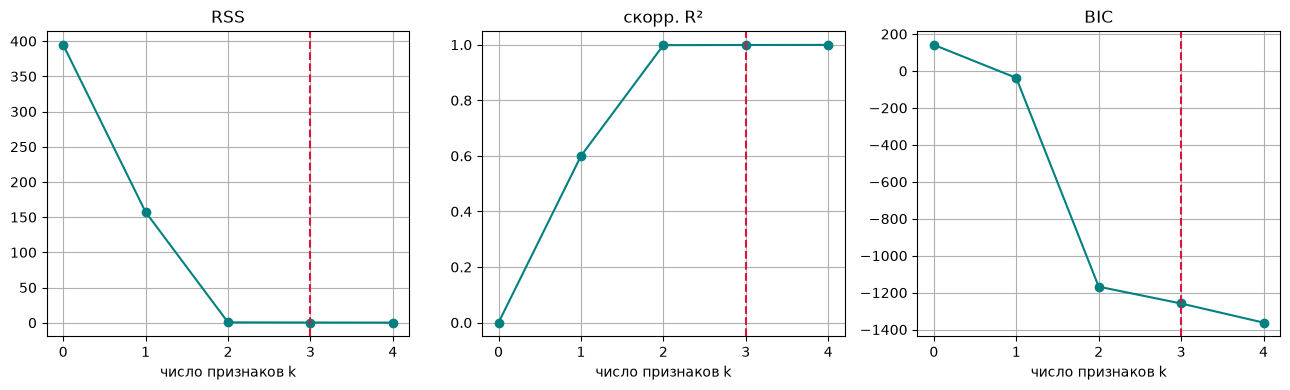

,k,признаки,RSS,adj R²,BIC
0,0,(только своб. член),394.6756,0.0000,141.2477
1,1,x1,157.2198,0.5996,-37.5379
2,2,"x1, x2",0.5380,0.9986,-1167.7621
3,3,"x1, x2, x3",0.3323,0.9991,-1258.8340
4,4,"x1, x2, x3, x4",0.1929,0.9995,-1362.3264


In [4]:
# Рис.2: RSS, adj R² и BIC лучшего подмножества каждой мощности
k_sel = int(sel['k'])
fig, ax = plt.subplots(1, 3, figsize=(13, 4))
for a, col, ttl in zip(ax, ['RSS','adj R²','BIC'], ['RSS','скорр. R²','BIC']):
    a.plot(best_per_k['k'], best_per_k[col], marker='o', color='teal')
    a.axvline(k_sel, ls='--', color='crimson'); a.set_xlabel('число признаков k'); a.set_title(ttl); a.grid(True)
plt.tight_layout(); plt.show()
best_per_k[['k','признаки','RSS','adj R²','BIC']].round(4)

### Выводы по заданию 2
Оптимальное сокращённое подмножество - {x1, x2, x3}. Оно лучшее по скорректированному R² и по BIC среди наборов мощности меньше четырёх. Решающий шаг алгоритма - переход от одного признака к двум; третий признак сохраняется, потому что всё ещё уменьшает RSS сильнее, чем это штрафует BIC.

## Задание 3. Взвешенная регрессия возраста отложений от глубины
По файлу cygage.txt оценить зависимость возраста исследуемых отложений от глубины залегания с весами наблюдений, сравнить её с обычным МНК и оценить качество.

In [5]:
# Задание 3: cygage.txt - взвешенная регрессия
d3 = pd.read_csv('cygage.txt', sep='\t')
print('cygage:', d3.shape, '| веса:', sorted(d3['Weight'].round(2).unique().tolist()))
X3 = d3[['Depth']].values; y3 = d3['calAge'].values; w3 = d3['Weight'].values
ols = LinearRegression().fit(X3, y3)
wls = LinearRegression().fit(X3, y3, sample_weight=w3)
def wr2(y, pred, w):
    ybar = np.average(y, weights=w)
    return 1 - (w*(y-pred)**2).sum() / (w*(y-ybar)**2).sum()
p_ols, p_wls = ols.predict(X3), wls.predict(X3)
tab3 = pd.DataFrame([
 {'модель':'МНК','a (своб. член)':ols.intercept_,'b (наклон)':ols.coef_[0],'R²':r2_score(y3,p_ols),'взвеш. R²':wr2(y3,p_ols,w3),'RMSE':mean_squared_error(y3,p_ols)**0.5},
 {'модель':'Взвешенный МНК','a (своб. член)':wls.intercept_,'b (наклон)':wls.coef_[0],'R²':r2_score(y3,p_wls),'взвеш. R²':wr2(y3,p_wls,w3),'RMSE':mean_squared_error(y3,p_wls)**0.5},
])
print(tab3.round(3).to_string(index=False))

cygage: (12, 3) | веса: [0.1, 0.5, 1.0]
        модель  a (своб. член)  b (наклон)    R²  взвеш. R²     RMSE
           МНК        1693.071      20.675 0.959      0.958  936.589
Взвешенный МНК         784.570      21.909 0.942      0.974 1113.990


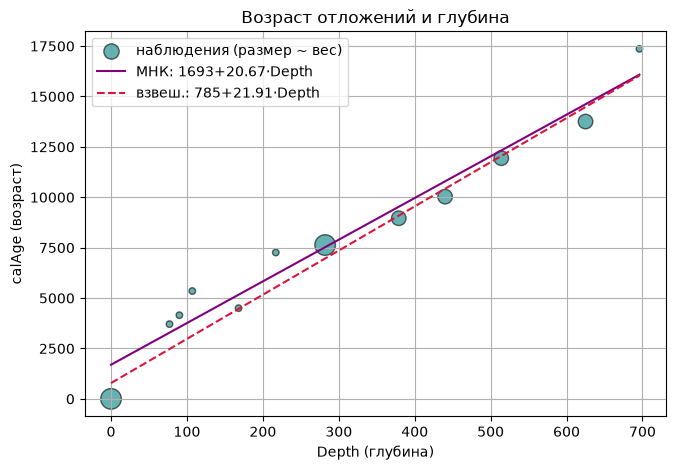

In [6]:
# Рис.3: возраст-глубина, размер точки ~ вес
plt.figure(figsize=(7.5,5))
plt.scatter(d3['Depth'], d3['calAge'], s=w3*220, color='teal', alpha=0.6, edgecolor='k', label='наблюдения (размер ~ вес)')
xs = np.linspace(d3['Depth'].min(), d3['Depth'].max(), 100).reshape(-1,1)
plt.plot(xs, ols.predict(xs), color='purple', label=f'МНК: {ols.intercept_:.0f}{ols.coef_[0]:+.2f}·Depth')
plt.plot(xs, wls.predict(xs), color='crimson', ls='--', label=f'взвеш.: {wls.intercept_:.0f}{wls.coef_[0]:+.2f}·Depth')
plt.xlabel('Depth (глубина)'); plt.ylabel('calAge (возраст)'); plt.title('Возраст отложений и глубина'); plt.legend(); plt.grid(True)
plt.show()

### Выводы по заданию 3
Обе модели показывают тесную связь возраста с глубиной. Для поставленной задачи подходит взвешенная регрессия: взвешенный R² = 0.974, наклон 21.91. Веса меняют в основном свободный член, а оценку скорости роста возраста с глубиной оставляют около 21-22 лет на единицу глубины.

## Задание 4. Гребневая регрессия на данных Лонгли
По файлу longley.csv, исключив Population, построить линейную регрессию отклика Employed и гребневую регрессию для λ = 10^(−3+0.2i), i = 0, …, 25. Сравнить ошибку на обучающей и тестовой выборках и объяснить результат.

In [7]:
# Задание 4: longley.csv - гребневая регрессия
d4 = pd.read_csv('longley.csv').drop(columns='Population')
feats4 = [c for c in d4.columns if c != 'Employed']
X4 = d4[feats4].values; y4 = d4['Employed'].values
print('longley:', d4.shape, '| признаки:', feats4, '| std(Employed)=', round(y4.std(ddof=1),2))
Xtr, Xte, ytr, yte = train_test_split(X4, y4, test_size=0.5, random_state=42)
sc4 = StandardScaler().fit(Xtr)
Ztr, Zte = sc4.transform(Xtr), sc4.transform(Xte)
print('Число обусловленности обуч. матрицы:', round(np.linalg.cond(Ztr), 1))
lam = [10**(-3 + 0.2*i) for i in range(26)]
ols4 = LinearRegression().fit(Ztr, ytr)
mse_tr_ols = mean_squared_error(ytr, ols4.predict(Ztr)); mse_te_ols = mean_squared_error(yte, ols4.predict(Zte))
rows4 = []
for L in lam:
    r = Ridge(alpha=L).fit(Ztr, ytr)
    rows4.append({'λ': L, 'MSE обуч.': mean_squared_error(ytr, r.predict(Ztr)), 'MSE тест': mean_squared_error(yte, r.predict(Zte))})
tab4 = pd.DataFrame(rows4)
print('МНК: MSE обуч=%.3f тест=%.3f (RMSE=%.3f, R²=%.3f)' % (mse_tr_ols, mse_te_ols, mse_te_ols**0.5, r2_score(yte, ols4.predict(Zte))))
print('Коэффициенты МНК (станд.):', dict(zip(feats4, ols4.coef_.round(2))))
show = tab4[tab4['λ'].apply(lambda L: any(abs(L-t)/t<1e-6 for t in [1e-3,1e-2,1e-1,1,10,100]))]
print(show.assign(**{'λ':show['λ'].round(3)}).round(3).to_string(index=False))

longley: (16, 6) | признаки: ['GNP.deflator', 'GNP', 'Unemployed', 'Armed.Forces', 'Year'] | std(Employed)= 3.51
Число обусловленности обуч. матрицы: 56.1
МНК: MSE обуч=0.006 тест=0.209 (RMSE=0.457, R²=0.981)
Коэффициенты МНК (станд.): {'GNP.deflator': np.float64(1.67), 'GNP': np.float64(-2.51), 'Unemployed': np.float64(-1.23), 'Armed.Forces': np.float64(-0.57), 'Year': np.float64(4.94)}
      λ  MSE обуч.  MSE тест
  0.001      0.006     0.220
  0.010      0.015     0.269
  0.100      0.035     0.306
  1.000      0.119     0.444
 10.000      1.259     0.959
100.000      7.762     6.567


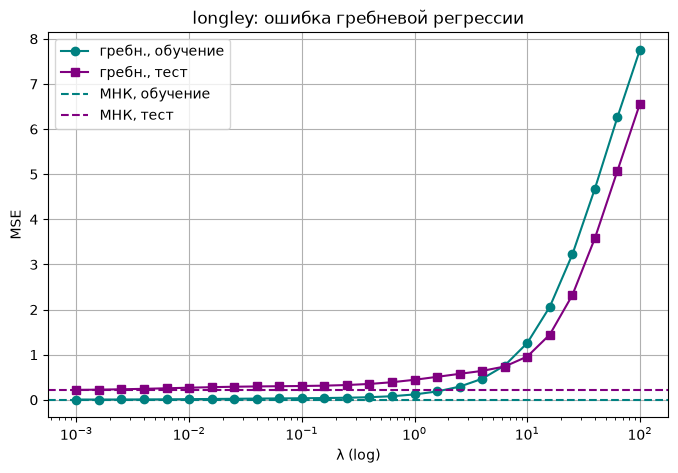

,признак,λ=0.001,λ=0.1,λ=1,λ=10,λ=100
0,GNP.deflator,1.692,1.501,1.196,0.789,0.219
1,GNP,-2.132,0.942,1.155,0.787,0.219
2,Unemployed,-1.176,-0.738,-0.402,0.038,0.043
3,Armed.Forces,-0.553,-0.355,-0.039,0.275,0.095
4,Year,4.512,1.378,1.100,0.762,0.215


In [8]:
# Рис.4: MSE гребневой регрессии от λ
plt.figure(figsize=(8,5))
plt.plot(tab4['λ'], tab4['MSE обуч.'], marker='o', color='teal', label='гребн., обучение')
plt.plot(tab4['λ'], tab4['MSE тест'], marker='s', color='purple', label='гребн., тест')
plt.axhline(mse_tr_ols, ls='--', color='teal', label='МНК, обучение')
plt.axhline(mse_te_ols, ls='--', color='purple', label='МНК, тест')
plt.xscale('log'); plt.xlabel('λ (log)'); plt.ylabel('MSE'); plt.title('longley: ошибка гребневой регрессии')
plt.legend(); plt.grid(True); plt.show()
# Табл.5: коэффициенты при нескольких λ
sel_l = [1e-3, 1e-1, 1, 10, 100]
ct = {'признак': feats4}
for L in sel_l:
    ct['λ=%g'%L] = Ridge(alpha=L).fit(Ztr, ytr).coef_.round(3)
pd.DataFrame(ct)

### Выводы по заданию 4
Мультиколлинеарность в ряде Лонгли есть, однако на случайном разбиении пополам гребневая регрессия не улучшает тестовую ошибку ни при одном λ из заданной сетки. Лучшей остаётся обычная линейная регрессия. Рост λ монотонно увеличивает и обучающую, и тестовую MSE, потому что общий временной тренд в признаках для Employed содержательный, и его сжатие добавляет смещение.

## Задание 5. Динамика европейских фондовых индексов
По ежедневным котировкам закрытия из eustock.csv построить общий график четырёх бирж, оценить линейный тренд каждой биржи отдельно и совместную модель, затем численно указать биржу с наибольшей динамикой.

In [9]:
# Задание 5: eustock.csv - динамика бирж
d5 = pd.read_csv('eustock.csv')
t5 = np.arange(len(d5)).reshape(-1,1)
print('eustock:', d5.shape, '| биржи:', list(d5.columns))
rows5 = []
for col in d5.columns:
    y = d5[col].values
    m = LinearRegression().fit(t5, y); r2 = m.score(t5, y)
    ml = LinearRegression().fit(t5, np.log(y)); pct = (np.exp(ml.coef_[0])-1)*100
    rows5.append({'биржа': col, 'наклон, пункт/день': m.coef_[0], 'R²': r2, 'темп, %/день': pct})
tab5 = pd.DataFrame(rows5).sort_values('наклон, пункт/день', ascending=False)
# совместная модель (длинная таблица)
long = pd.concat([pd.DataFrame({'y':d5[c].values,'t':t5.ravel(),'ex':c}) for c in d5.columns], ignore_index=True)
Xc = np.column_stack([long['t'], pd.get_dummies(long['ex'], drop_first=True).astype(float)])
rc = LinearRegression().fit(Xc, long['y']); r2_common = rc.score(Xc, long['y'])
Xf = np.column_stack([pd.get_dummies(long['ex']).astype(float), *[long['t']*(long['ex']==c) for c in d5.columns]])
rf = LinearRegression(fit_intercept=False).fit(Xf, long['y']); r2_full = rf.score(Xf, long['y'])
print(tab5.round(4).to_string(index=False))
print('Совместная (общий наклон): b=%.3f, R²=%.3f | своб. наклоны: R²=%.3f' % (rc.coef_[0], r2_common, r2_full))

eustock: (1860, 4) | биржи: ['DAX', 'SMI', 'CAC', 'FTSE']
биржа  наклон, пункт/день     R²  темп, %/день
  SMI              2.7598 0.7944        0.0776
  DAX              1.7294 0.7331        0.0623
 FTSE              1.6748 0.8482        0.0451
  CAC              0.7868 0.5303        0.0310
Совместная (общий наклон): b=1.738, R²=0.730 | своб. наклоны: R²=0.817


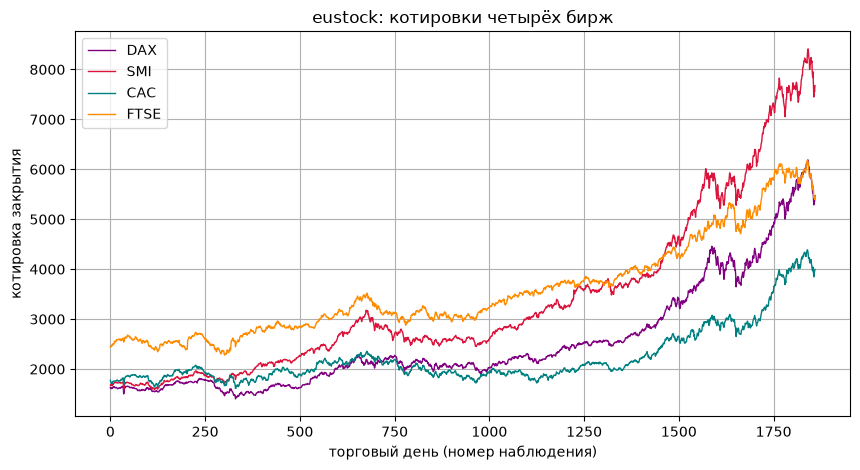

,биржа,"наклон, пункт/день",R²,"темп, %/день"
1,SMI,2.7598,0.7944,0.0776
0,DAX,1.7294,0.7331,0.0623
3,FTSE,1.6748,0.8482,0.0451
2,CAC,0.7868,0.5303,0.0310


In [10]:
# Рис.5: котировки четырёх бирж
plt.figure(figsize=(10,5))
for col, c in zip(d5.columns, ['purple','crimson','teal','darkorange']):
    plt.plot(t5.ravel(), d5[col], color=c, label=col, lw=1)
plt.xlabel('торговый день (номер наблюдения)'); plt.ylabel('котировка закрытия'); plt.title('eustock: котировки четырёх бирж')
plt.legend(); plt.grid(True); plt.show()
tab5.round(4)

### Выводы по заданию 5
Наибольшая динамика у биржи SMI. Она лидирует и по приросту в пунктах (2.760 за день), и по логарифмическому темпу (0.0776% за день). Наименьшая динамика у CAC.

## Задание 6. Квартальная прибыль Johnson & Johnson
По ряду JohnsonJohnson.csv сравнить динамику квартальной прибыли, построить отдельные и совместную линейные регрессии и дать прогноз на 2016 год по каждому кварталу и в среднем за год.

In [11]:
# Задание 6: JohnsonJohnson.csv - квартальная прибыль
jj = pd.read_csv('JohnsonJohnson.csv')
jj['year'] = jj['index'].str[:4].astype(int)
jj['q'] = jj['index'].str[-1].astype(int)
print('JohnsonJohnson:', jj.shape, '| годы', jj['year'].min(), '-', jj['year'].max())
rows6 = []
for q in [1,2,3,4]:
    sub = jj[jj['q']==q]
    m = LinearRegression().fit(sub[['year']], sub['value']); r2 = m.score(sub[['year']], sub['value'])
    rows6.append({'квартал': q, 'наклон/год': m.coef_[0], 'R²': r2, 'прогноз 2016': m.intercept_ + m.coef_[0]*2016})
tab6 = pd.DataFrame(rows6)
Xc6 = np.column_stack([jj['year'], pd.get_dummies(jj['q'], drop_first=True).astype(float)])
rc6 = LinearRegression().fit(Xc6, jj['value'])
rss_sep = sum(((jj[jj['q']==q]['value'] - LinearRegression().fit(jj[jj['q']==q][['year']], jj[jj['q']==q]['value']).predict(jj[jj['q']==q][['year']]))**2).sum() for q in [1,2,3,4])
rss_joint = ((jj['value'] - rc6.predict(Xc6))**2).sum()
print(tab6.round(3).to_string(index=False))
print('Средний прогноз 2016:', round(tab6['прогноз 2016'].mean(),2), '| общий наклон', round(rc6.coef_[0],3), 'R²', round(rc6.score(Xc6,jj['value']),3))
print('RSS отдельных=%.1f, совместной=%.1f' % (rss_sep, rss_joint))

JohnsonJohnson: (84, 4) | годы 1960 - 1980
 квартал  наклон/год    R²  прогноз 2016
       1       0.695 0.836        36.760
       2       0.685 0.892        36.489
       3       0.704 0.865        37.654
       4       0.535 0.928        28.794
Средний прогноз 2016: 34.92 | общий наклон 0.655 R² 0.865
RSS отдельных=193.2, совместной=208.1


/Library/Frameworks/Python.framework/Versions/3.15/lib/python3.15/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.15/lib/python3.15/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.15/lib/python3.15/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.15/lib/python3.15/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


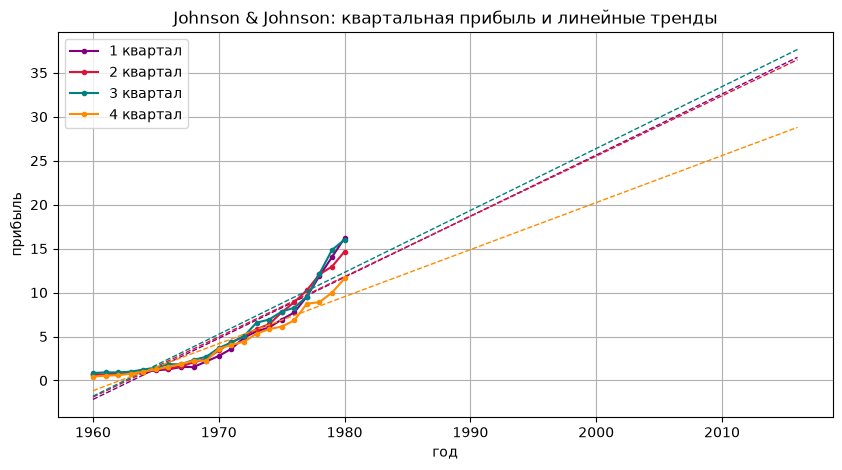

,квартал,наклон/год,R²,прогноз 2016
0,1,0.695,0.836,36.760
1,2,0.685,0.892,36.489
2,3,0.704,0.865,37.654
3,4,0.535,0.928,28.794


In [12]:
# Рис.6: квартальная прибыль и тренды
plt.figure(figsize=(10,5))
for q, c in zip([1,2,3,4], ['purple','crimson','teal','darkorange']):
    sub = jj[jj['q']==q]; m = LinearRegression().fit(sub[['year']], sub['value'])
    plt.plot(sub['year'], sub['value'], marker='.', color=c, label=f'{q} квартал')
    xs = np.array([[sub['year'].min()],[2016]]); plt.plot(xs.ravel(), m.predict(xs), ls='--', color=c, lw=1)
plt.xlabel('год'); plt.ylabel('прибыль'); plt.title('Johnson & Johnson: квартальная прибыль и линейные тренды')
plt.legend(); plt.grid(True); plt.show()
tab6.round(3)

### Выводы по заданию 6
Наибольшая динамика доходности - в III квартале, наименьшая - в IV. Прогноз линейной модели на 2016 год: I - 36.76, II - 36.49, III - 37.65, IV - 28.79. Средняя прибыль по году - 34.92.

## Задание 7. Тормозной путь автомобиля
По данным cars.csv построить регрессию тормозного пути от скорости, показать её на графике и оценить путь при скорости 40 миль в час.

In [13]:
# Задание 7: cars.csv - тормозной путь
cars = pd.read_csv('cars.csv')
print('cars:', cars.shape, '| speed', cars['speed'].min(),'-',cars['speed'].max(), '| dist', cars['dist'].min(),'-',cars['dist'].max())
m7 = LinearRegression().fit(cars[['speed']], cars['dist']); r2_7 = m7.score(cars[['speed']], cars['dist'])
pred40 = m7.intercept_ + m7.coef_[0]*40
print('dist = %.2f %+.2f·speed | R²=%.3f | прогноз при 40 миль/ч = %.1f фута' % (m7.intercept_, m7.coef_[0], r2_7, pred40))

cars: (50, 2) | speed 4 - 25 | dist 2 - 120
dist = -17.58 +3.93·speed | R²=0.651 | прогноз при 40 миль/ч = 139.7 фута


/Library/Frameworks/Python.framework/Versions/3.15/lib/python3.15/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.15/lib/python3.15/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


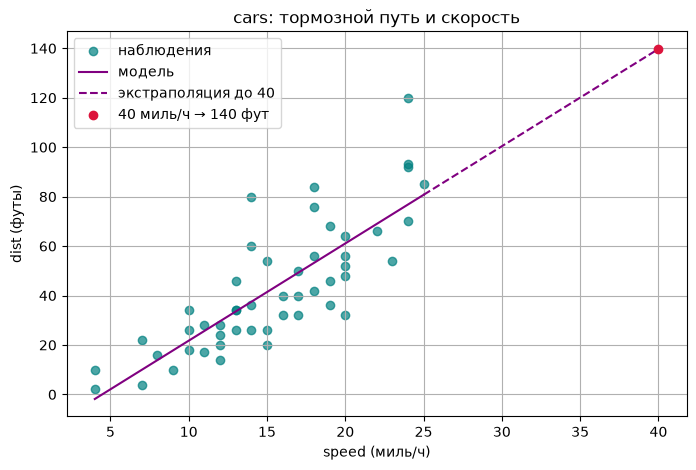

In [14]:
# Рис.7: тормозной путь и экстраполяция до 40
plt.figure(figsize=(8,5))
plt.scatter(cars['speed'], cars['dist'], color='teal', alpha=0.7, label='наблюдения')
xs1 = np.linspace(cars['speed'].min(), cars['speed'].max(), 50).reshape(-1,1)
xs2 = np.linspace(cars['speed'].max(), 40, 50).reshape(-1,1)
plt.plot(xs1, m7.predict(xs1), color='purple', label='модель')
plt.plot(xs2, m7.predict(xs2), color='purple', ls='--', label='экстраполяция до 40')
plt.scatter([40],[pred40], color='crimson', zorder=5, label=f'40 миль/ч → {pred40:.0f} фут')
plt.xlabel('speed (миль/ч)'); plt.ylabel('dist (футы)'); plt.title('cars: тормозной путь и скорость'); plt.legend(); plt.grid(True)
plt.show()

### Выводы по заданию 7
Линейная модель оценивает тормозной путь при 40 милях в час в 139.7 фута. R² = 0.651. Результат относится к продолжению прямой за пределы 4-25 миль в час, на которых собраны измерения.

## Задание 8. SVM-регрессия и ширина ε-трубки
На данных svmdata6.txt построить SVR с ядром RBF и C = 1 и проследить, как средний квадрат ошибки на обучающей выборке зависит от ε.

In [15]:
# Задание 8: svmdata6.txt - SVR и ширина eps-трубки
d8 = pd.read_csv('svmdata6.txt', sep='\t')
X8 = d8[['X']].values; y8 = d8['Y'].values
print('svmdata6:', d8.shape, '| X', d8['X'].min(),'-',d8['X'].max(), '| Y', round(d8['Y'].min(),2),'-',round(d8['Y'].max(),2), '| var(Y)=', round(d8['Y'].var(),3))
eps_grid = np.linspace(0, 1.5, 31)
rows8 = []
for e in eps_grid:
    s = SVR(kernel='rbf', C=1.0, epsilon=e).fit(X8, y8)
    rows8.append({'eps': e, 'MSE': mean_squared_error(y8, s.predict(X8)), 'опорных векторов': len(s.support_)})
tab8 = pd.DataFrame(rows8)
best = tab8.loc[tab8['MSE'].idxmin()]
print('Минимум MSE=%.4f при eps=%.2f (опорных %d)' % (best['MSE'], best['eps'], best['опорных векторов']))
print('eps=0: MSE=%.4f, опорных %d | eps=1.5: MSE=%.4f, опорных %d' % (tab8.iloc[0]['MSE'], tab8.iloc[0]['опорных векторов'], tab8.iloc[-1]['MSE'], tab8.iloc[-1]['опорных векторов']))

svmdata6: (101, 2) | X 0.0 - 5.0 | Y -1.2 - 1.2 | var(Y)= 0.524
Минимум MSE=0.0104 при eps=0.05 (опорных 75)
eps=0: MSE=0.0111, опорных 101 | eps=1.5: MSE=0.5374, опорных 0


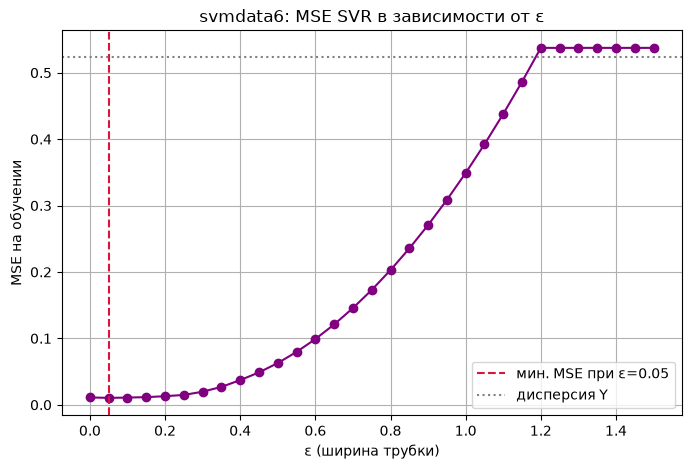

,eps,MSE,опорных векторов
0,0.00,0.0111,101
3,0.15,0.0115,15
6,0.30,0.0197,3
9,0.45,0.0488,2
12,0.60,0.0990,2
15,0.75,0.1729,2
18,0.90,0.2707,2
21,1.05,0.3922,2
24,1.20,0.5374,0
27,1.35,0.5374,0


In [16]:
# Рис.8: MSE SVR от eps
plt.figure(figsize=(8,5))
plt.plot(tab8['eps'], tab8['MSE'], marker='o', color='purple')
plt.axvline(best['eps'], ls='--', color='crimson', label=f"мин. MSE при ε={best['eps']:.2f}")
plt.axhline(d8['Y'].var(), ls=':', color='gray', label='дисперсия Y')
plt.xlabel('ε (ширина трубки)'); plt.ylabel('MSE на обучении'); plt.title('svmdata6: MSE SVR в зависимости от ε')
plt.legend(); plt.grid(True); plt.show()
tab8.iloc[::3].round(4)

### Выводы по заданию 8
Параметр ε управляет тем, какие остатки модель согласна игнорировать. Слишком узкая трубка при C = 1 не даёт наименьшей MSE на обучении. После минимума дальнейшее увеличение ε ухудшает квадратичную точность и в пределе сводит SVR к константе.

## Задание 9. Сравнение дерева, линейной регрессии и SVM для re78
По файлу nsw74psid1.csv построить регрессионное дерево, линейную регрессию и SVM-регрессию для заработка re78, сравнить качество и выбрать модель.

In [17]:
# Задание 9: nsw74psid1.csv - дерево, линейная регрессия и SVM для re78
d9 = pd.read_csv('nsw74psid1.csv')
y9 = d9['re78'].values; X9 = d9.drop(columns='re78')
print('nsw74psid1:', d9.shape, '| re78 среднее %.0f, std %.0f | нулевых %.1f%%' % (y9.mean(), y9.std(), (y9==0).mean()*100))
Xtr, Xte, ytr, yte = train_test_split(X9, y9, test_size=0.3, random_state=42)
# дерево: глубина по 5-блочной CV R²
kf = KFold(5, shuffle=True, random_state=42)
depths = range(1, 16)
cv_r2 = [cross_val_score(DecisionTreeRegressor(max_depth=dd, random_state=42), Xtr, ytr, cv=kf, scoring='r2').mean() for dd in depths]
best_d = list(depths)[int(np.argmax(cv_r2))]
tree = DecisionTreeRegressor(max_depth=best_d, random_state=42).fit(Xtr, ytr)
# линейная
lin = LinearRegression().fit(Xtr, ytr)
# SVM: стандартизация X и y, перебор C и eps по 3-блочной CV RMSE
ys = StandardScaler().fit(ytr.reshape(-1,1))
grid = GridSearchCV(make_pipeline(StandardScaler(), SVR(kernel='rbf')),
                    {'svr__C':[0.3,1,3,10], 'svr__epsilon':[0.05,0.1,0.2]},
                    cv=3, scoring='neg_root_mean_squared_error')
grid.fit(Xtr, ys.transform(ytr.reshape(-1,1)).ravel())
svr_best = grid.best_estimator_
def metr(model, scaled=False):
    pred = model.predict(Xte)
    if scaled: pred = ys.inverse_transform(pred.reshape(-1,1)).ravel()
    return r2_score(yte, pred), mean_squared_error(yte, pred)**0.5, mean_absolute_error(yte, pred)
print('Дерево глубины', best_d, '(CV R²=%.3f)' % max(cv_r2), '| SVR:', grid.best_params_)
tab9 = pd.DataFrame([
 dict(zip(['модель','R²','RMSE','MAE'], ['Дерево решений', *metr(tree)])),
 dict(zip(['модель','R²','RMSE','MAE'], ['Линейная регрессия', *metr(lin)])),
 dict(zip(['модель','R²','RMSE','MAE'], ['SVM-регрессия', *metr(svr_best, True)])),
])
const_rmse = mean_squared_error(yte, np.full_like(yte, ytr.mean(), dtype=float))**0.5
print(tab9.round(1).to_string(index=False)); print('Константа (среднее обуч.): RMSE=%.0f' % const_rmse)

nsw74psid1: (2675, 10) | re78 среднее 20502, std 15630 | нулевых 12.4%
Дерево глубины 3 (CV R²=0.513) | SVR: {'svr__C': 3, 'svr__epsilon': 0.2}
            модель  R²    RMSE    MAE
    Дерево решений 0.5 10694.2 7115.3
Линейная регрессия 0.6 10149.0 6484.6
     SVM-регрессия 0.6 10163.4 6469.3
Константа (среднее обуч.): RMSE=15710


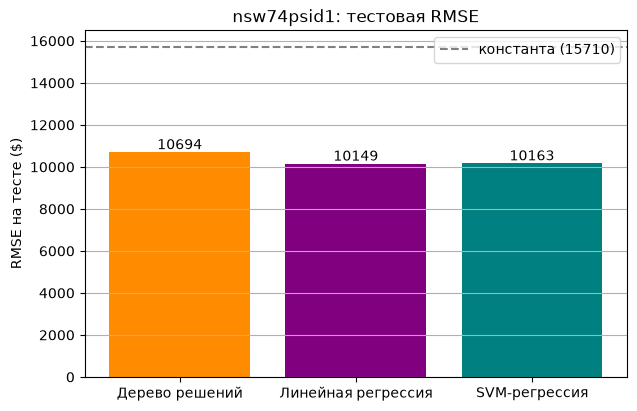

,модель,R²,RMSE,MAE
0,Дерево решений,0.5,10694.2,7115.3
1,Линейная регрессия,0.6,10149.0,6484.6
2,SVM-регрессия,0.6,10163.4,6469.3


In [18]:
# Рис.9: тестовая RMSE трёх моделей
plt.figure(figsize=(7,4.5))
plt.bar(tab9['модель'], tab9['RMSE'], color=['darkorange','purple','teal'])
plt.axhline(const_rmse, ls='--', color='gray', label=f'константа ({const_rmse:.0f})')
for i,v in enumerate(tab9['RMSE']): plt.text(i, v+150, f'{v:.0f}', ha='center')
plt.ylabel('RMSE на тесте ($)'); plt.title('nsw74psid1: тестовая RMSE'); plt.legend(); plt.grid(True, axis='y')
plt.show()
tab9.round(1)

In [19]:
# Табл.9: вклад признаков (станд. коэффициент МНК и важность дерева)
sx = StandardScaler().fit(Xtr)
lin_std = LinearRegression().fit(sx.transform(Xtr), ytr)
contrib = pd.DataFrame({'признак': X9.columns,
                        'коэф. МНК (на 1 ст.откл.)': lin_std.coef_,
                        'важность дерева, %': tree.feature_importances_*100}).sort_values('важность дерева, %', ascending=False)
print(contrib.round(1).to_string(index=False))
contrib.round(1)

признак  коэф. МНК (на 1 ст.откл.)  важность дерева, %
   re75                     7188.9                82.9
   re74                     4380.6                17.1
    trt                      398.9                 0.0
    age                     -597.8                 0.0
   educ                     1833.5                 0.0
  black                     -198.9                 0.0
   hisp                      318.4                 0.0
   marr                      600.6                 0.0
  nodeg                       66.5                 0.0


,признак,коэф. МНК (на 1 ст.откл.),"важность дерева, %"
8,re75,7188.9,82.9
7,re74,4380.6,17.1
0,trt,398.9,0.0
1,age,-597.8,0.0
2,educ,1833.5,0.0
3,black,-198.9,0.0
4,hisp,318.4,0.0
5,marr,600.6,0.0
6,nodeg,66.5,0.0


### Выводы по заданию 9
Оптимальной выбрана линейная регрессия. На тестовой выборке её RMSE и R² не хуже, чем у настроенной SVM-регрессии, а модель проще и не показывает дополнительного подгона под обучение. Регрессионное дерево глубины 3 использует только re74 и re75 и уступает обеим гладким моделям. Доля объяснённой дисперсии около 0.58 ожидаема: в отклике много нулей и крупный индивидуальный разброс, который признаки 1974-1975 годов не закрывают.